# 5. Resultados en prueba y coste de inferencia

Comparamos los tres modelos de referencia y la variante en prueba con los umbrales elegidos en validación. Cargamos la partición de prueba y el manifiesto de la variante, que identifica sus pesos, umbrales y parámetros de entrada.

In [1]:
import os

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.ticker import FuncFormatter
from torch.utils.data import DataLoader

from photovoltaic_xai import CLASS_NAMES, MODEL_NAMES
from photovoltaic_xai.dataset import PairedELTransform, PVELADDataset
from photovoltaic_xai.metrics import compute_metrics, paired_group_bootstrap
from photovoltaic_xai.models import (
    benchmark_model,
    load_trained_model,
    predict,
    time_cuda,
)
from photovoltaic_xai.notebook_support import decimal_label, project_root, show_figure
from photovoltaic_xai.preparation import load_preparation
from photovoltaic_xai.variant import VariantDataset, load_variant, load_variant_manifest

PROJECT_ROOT = project_root()
OUTPUTS = PROJECT_ROOT / "outputs"
manifest_path = OUTPUTS / "variant_reference_global/manifest.json"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

prepared = load_preparation(PROJECT_ROOT)
manifest = load_variant_manifest(manifest_path, prepared, root=PROJECT_ROOT)
normalization = prepared["normalization"]
test_records = [record for record in prepared["records"] if record["split"] == "test"]
expected_labels = np.asarray([record["labels"] for record in test_records], dtype=np.float32)

## Predicciones de las referencias

Calculamos las predicciones de las tres referencias con las imágenes de prueba sin aumentos.

In [2]:
transform = PairedELTransform(512, mean=normalization["mean"], std=normalization["std"])
test_dataset = PVELADDataset(test_records, PROJECT_ROOT, transform, allow_test=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

reference_runs, reference_predictions = {}, {}
for name in MODEL_NAMES:
    directory = OUTPUTS / "experiments" / name
    model, run = load_trained_model(directory, prepared, device=device)
    predictions = predict(model, test_loader, device=device)
    del model
    reference_runs[name], reference_predictions[name] = run, predictions

## Predicciones de la variante

Obtenemos los logits de la fusión y de la rama global para las mismas imágenes.

In [3]:
model = load_variant(manifest_path, device=device, root=PROJECT_ROOT, manifest=manifest)
dataset = VariantDataset(test_records, PROJECT_ROOT, normalization, allow_test=True)
loader = DataLoader(dataset, batch_size=4, shuffle=False)
logits, global_logits = [], []
with torch.inference_mode(), torch.autocast(device.type, enabled=False):
    for batch in loader:
        outputs = model(*(batch[key].to(device) for key in ("image", "tiles", "tile_valid")))
        logits.append(outputs["logits"].cpu().numpy())
        global_logits.append(outputs["global_logits"].cpu().numpy())
variant_predictions = {
    "logits": np.concatenate(logits),
    "global_logits": np.concatenate(global_logits),
}
del model

## Métricas globales en prueba

El acierto completo exige acertar todas las etiquetas de una imagen. La tabla dedica columnas a los aciertos completos en imágenes multietiqueta y a las falsas alarmas en sanas, que se cuentan cuando el modelo predice al menos un defecto. La fila `variant_global` corresponde a la rama global de la variante.

In [4]:
reports = {
    name: compute_metrics(
        result["labels"],
        result["probabilities"],
        reference_runs[name]["metrics"]["thresholds"],
        logits=result["logits"],
    )
    for name, result in reference_predictions.items()
}
for name, key, threshold_key in (
    ("variant_global", "global_logits", "global_thresholds"),
    ("variant", "logits", "thresholds"),
):
    logits = variant_predictions[key]
    probabilities = torch.from_numpy(logits).sigmoid().numpy()
    reports[name] = compute_metrics(
        expected_labels, probabilities, manifest[threshold_key], logits=logits
    )

comparison = pd.DataFrame({name: report["overall"] for name, report in reports.items()}).T
for name, report in reports.items():
    healthy, multilabel = report["healthy"], report["strata"]["multilabel"]
    comparison.loc[name, "Sanas"] = healthy["num_samples"]
    comparison.loc[name, "Falsas alarmas (sanas)"] = healthy["false_positive_rate_any_label"]
    comparison.loc[name, "Multietiqueta"] = multilabel["num_images"]
    comparison.loc[name, "Acierto completo (multietiqueta)"] = multilabel["subset_accuracy"]
    if healthy["false_positive_rate_any_label"] is not None:
        comparison.loc[name, "Número de falsas alarmas"] = round(
            healthy["num_samples"] * healthy["false_positive_rate_any_label"]
        )
    if multilabel["subset_accuracy"] is not None:
        comparison.loc[name, "Número de aciertos multietiqueta"] = round(
            multilabel["num_images"] * multilabel["subset_accuracy"]
        )
display(comparison.drop(columns="num_classes"))

,map,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,hamming_loss,subset_accuracy,Sanas,Falsas alarmas (sanas),Multietiqueta,Acierto completo (multietiqueta),Número de falsas alarmas,Número de aciertos multietiqueta
efficientnet_b0,0.962995,0.944782,0.920239,0.931119,0.962757,0.935270,0.948814,0.012673,0.930823,1710.0,0.028655,364.0,0.524725,49.0,191.0
convnext_tiny,0.966588,0.939585,0.929170,0.934246,0.955666,0.944376,0.949988,0.012488,0.931009,1710.0,0.031579,364.0,0.590659,54.0,215.0
swin_t,0.966493,0.934550,0.933345,0.933912,0.951104,0.943145,0.947108,0.013229,0.928598,1710.0,0.027485,364.0,0.615385,47.0,224.0
variant_global,0.966588,0.939585,0.929170,0.934246,0.955666,0.944376,0.949988,0.012488,0.931009,1710.0,0.031579,364.0,0.590659,54.0,215.0
variant,0.970645,0.944671,0.938238,0.941380,0.955545,0.952252,0.953895,0.011560,0.935460,1710.0,0.020468,364.0,0.634615,35.0,231.0


La variante obtiene la mayor mAP (97,06 %) y el F1 macro más alto (94,14 %). Respecto a su rama global, pasa de 215 a 231 aciertos completos en imágenes multietiqueta y de 54 a 35 falsas alarmas en sanas.

## AP y F1 por defecto en prueba

Los paneles comparan las tres referencias y la variante para cada defecto. Arriba, el AP indica hasta qué punto el modelo da puntuaciones más altas a las imágenes con el defecto. Abajo, el F1 combina la precisión y la sensibilidad obtenidas con los umbrales de validación.

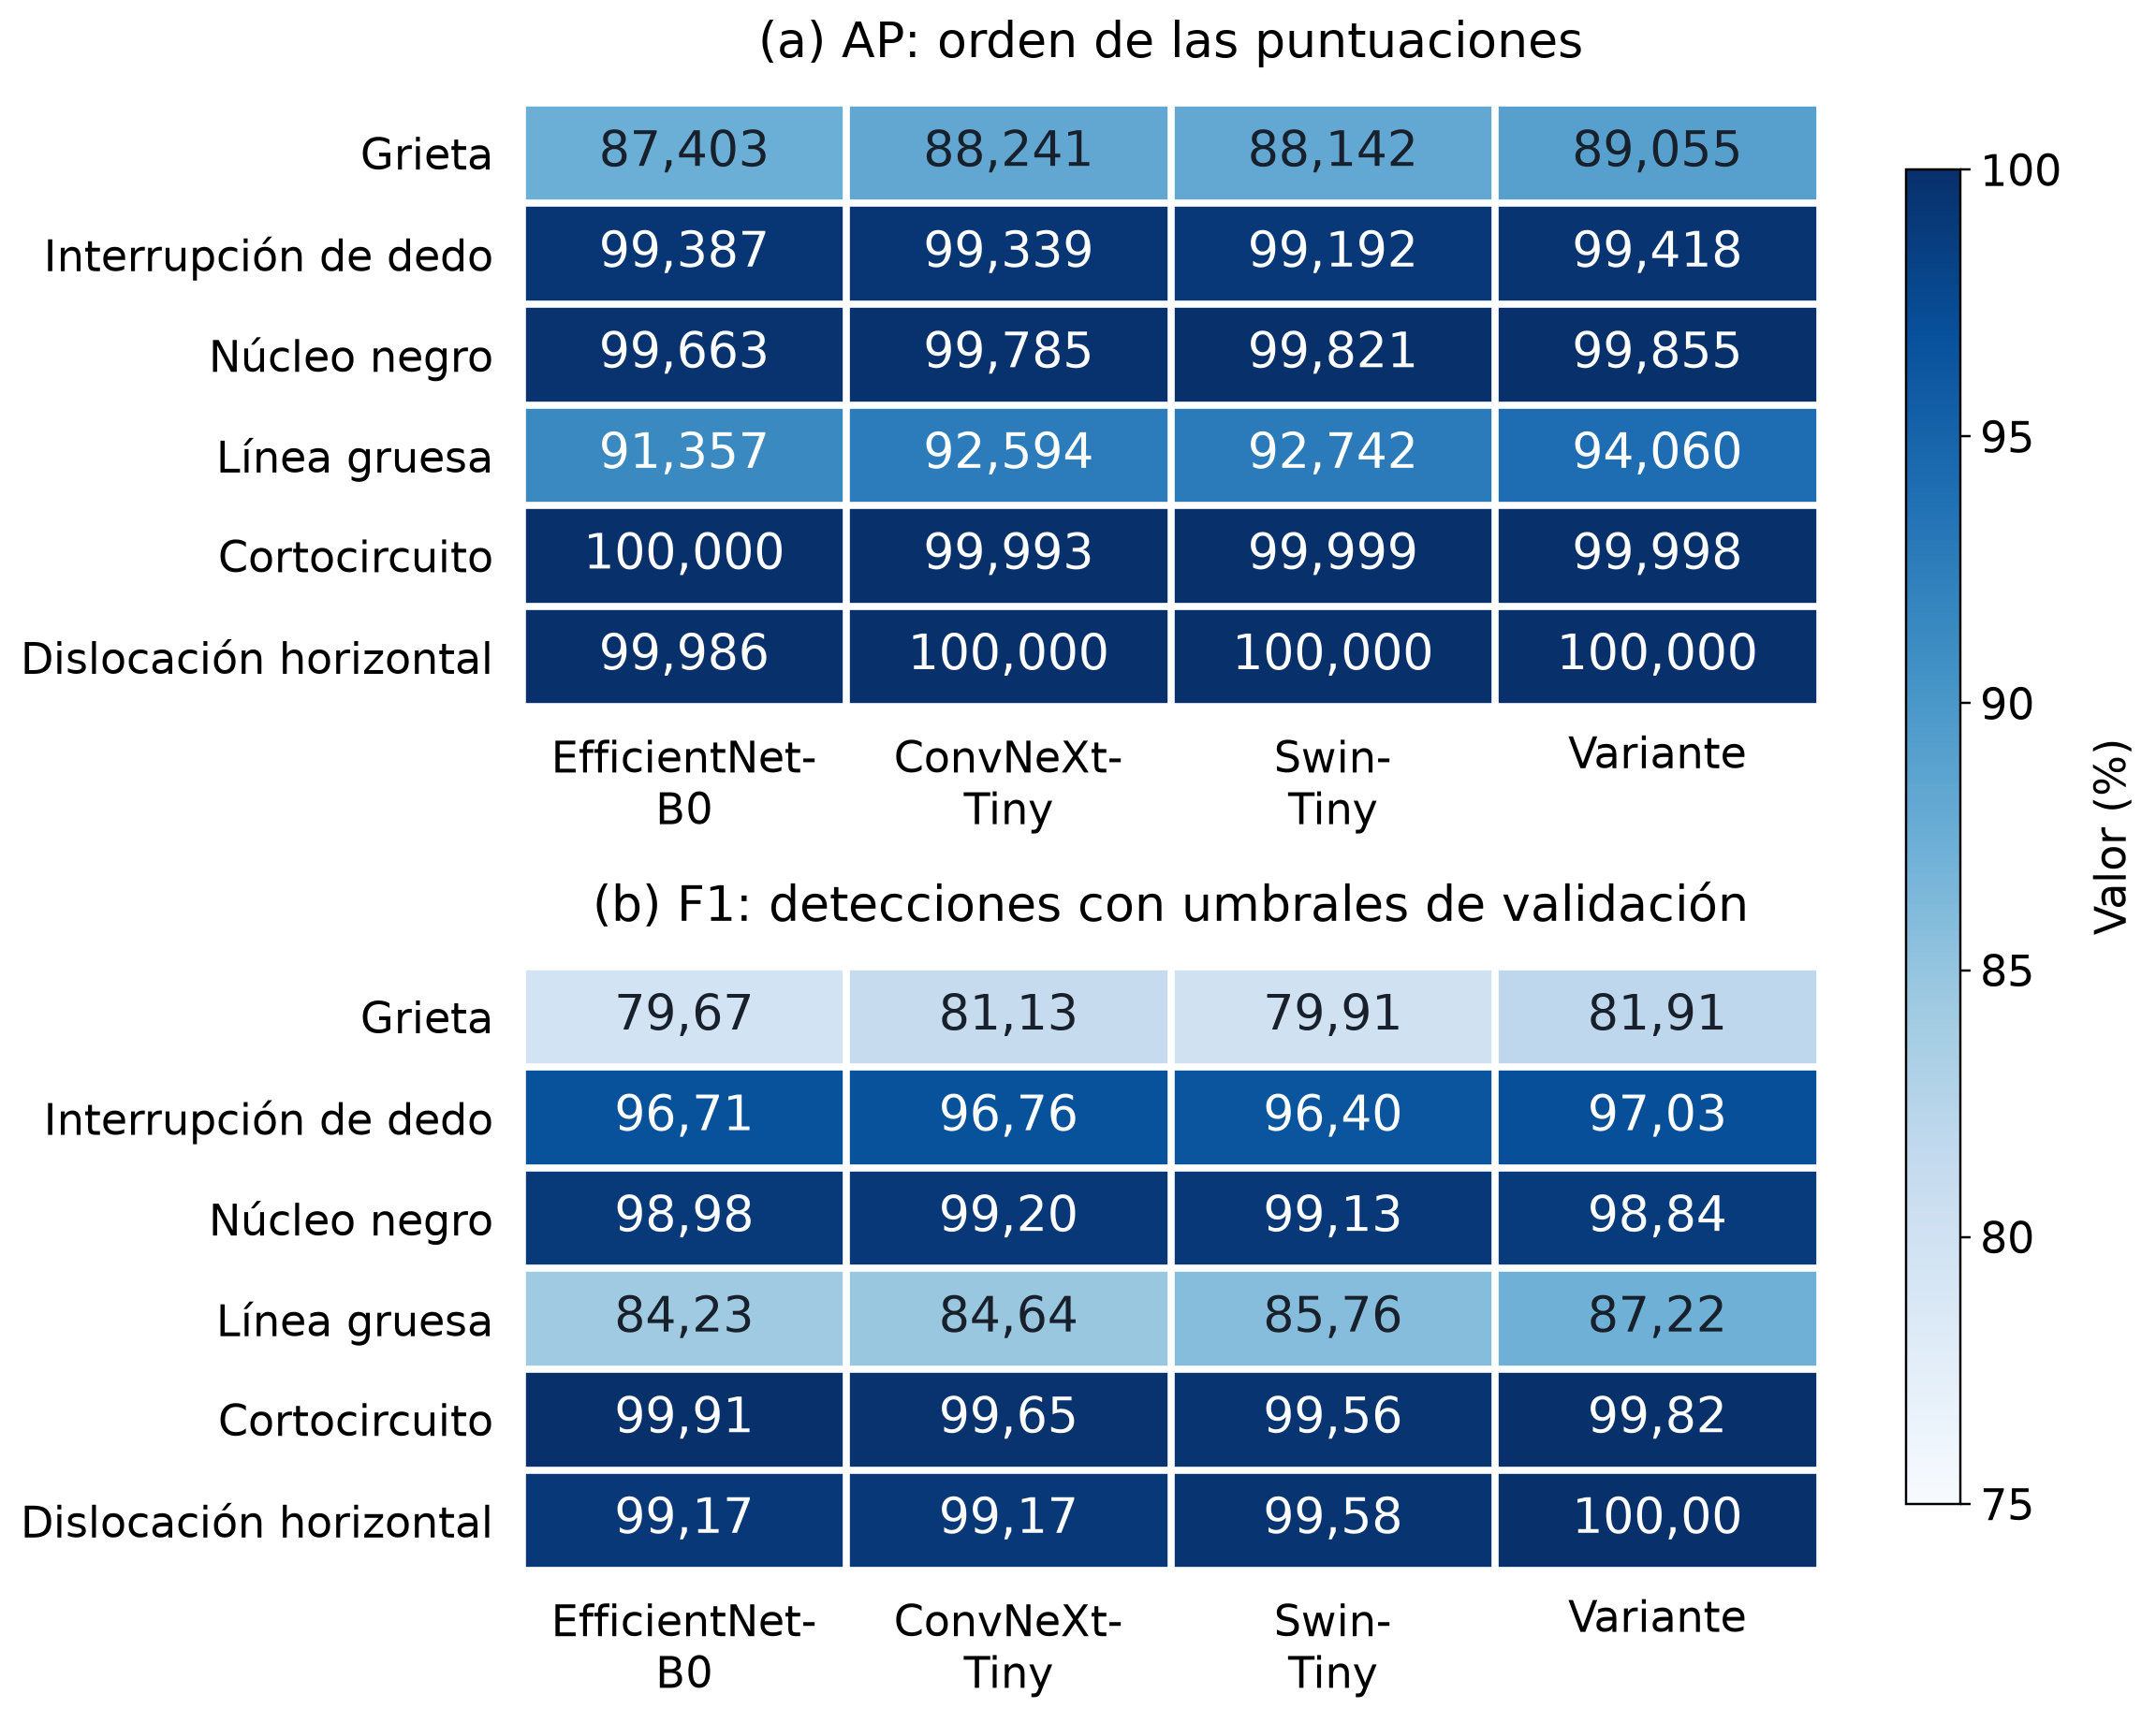

In [5]:
ap_models = [*MODEL_NAMES, "variant"]
titles = ["EfficientNet-B0", "ConvNeXt-Tiny", "Swin-Tiny", "Variante"]
labels = [
    "Grieta",
    "Interrupción de dedo",
    "Núcleo negro",
    "Línea gruesa",
    "Cortocircuito",
    "Dislocación horizontal",
]
per_class = [pd.DataFrame(reports[name]["per_class"]).set_index("class") for name in ap_models]
ap_values, f1_values = (
    np.column_stack([table.loc[list(CLASS_NAMES), metric] for table in per_class]) * 100
    for metric in ("average_precision", "f1")
)
colour_min = min(75, 5 * np.floor(min(ap_values.min(), f1_values.min()) / 5))
panels = [
    (ap_values, 3, "(a) AP: orden de las puntuaciones"),
    (f1_values, 2, "(b) F1: detecciones con umbrales de validación"),
]
with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 15}):
    fig, axes = plt.subplots(2, 1, figsize=(10.5, 8.1))
    for ax, (values, decimals, title) in zip(axes, panels, strict=True):
        rendered = ax.imshow(values, cmap="Blues", vmin=colour_min, vmax=100, aspect="auto")
        ax.set_title(title, fontsize=17, pad=16)
        ax.set_xticks(range(len(titles)), [name.replace("-", "-\n", 1) for name in titles])
        ax.set_yticks(range(len(labels)), labels)
        ax.tick_params(length=0, pad=10)
        for (row, col), value in np.ndenumerate(values):
            ax.text(
                col,
                row,
                f"{value:.{decimals}f}".replace(".", ","),
                ha="center",
                va="center",
                fontsize=17,
                color="white" if value > 90 else "#17202b",
            )
        ax.set_xticks(np.arange(-0.5, len(titles), 1), minor=True)
        ax.set_yticks(np.arange(-0.5, len(labels), 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=2.5)
        ax.tick_params(which="minor", bottom=False, left=False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    fig.subplots_adjust(left=0.28, right=0.88, top=0.94, bottom=0.06, hspace=0.43)
    bar = fig.colorbar(rendered, cax=fig.add_axes([0.92, 0.10, 0.025, 0.80]))
    bar.set_label("Valor (%)", labelpad=11)
    bar.set_ticks(np.linspace(colour_min, 100, 6))
    bar.ax.yaxis.set_major_formatter(FuncFormatter(decimal_label))
    show_figure(fig)

Frente a ConvNeXt, el AP de la variante sube del 88,24 % al 89,06 % en grieta y del 92,59 % al 94,06 % en línea gruesa. En núcleo negro, el F1 baja del 99,20 % al 98,84 %.

## Incertidumbre de la mejora frente a la rama global

En la tabla global, las filas `variant_global` y `convnext_tiny` tienen los mismos valores. Para estimar cuánto aporta la fusión, comparamos la variante con su propia rama global. Calculamos intervalos del 95 % con 5000 réplicas, usando los mismos grupos de imágenes para ambas salidas en cada réplica.

In [6]:
contrasts = paired_group_bootstrap(
    expected_labels,
    [record["group_id"] for record in test_records],
    (variant_predictions["logits"], manifest["thresholds"]),
    (variant_predictions["global_logits"], manifest["global_thresholds"]),
    replicates=5000,
    seed=20261109,
)
display(pd.DataFrame(contrasts))

,metric,difference_pp,ci95_lower_pp,ci95_upper_pp,valid_replicates
0,map,0.405656,0.224315,0.592964,5000
1,f1_macro,0.713418,0.235864,1.249933,5000
2,f1_micro,0.390784,0.096804,0.703662,5000
3,subset_accuracy,0.445104,0.019931,0.869408,5000
4,multilabel_subset_accuracy,4.395604,1.408451,7.377049,5000
5,crack_ap,0.814021,0.128357,1.552117,5000
6,healthy_false_positive_rate,-1.111111,-1.777251,-0.466997,5000


La mAP sube 0,406 puntos porcentuales, con un intervalo del 95 % de 0,224 a 0,593. Los siete intervalos excluyen el cero. El de falsas alarmas en sanas es negativo, en línea con la reducción de la tabla global.

## Medición del coste de inferencia

Medimos en GPU con una imagen por lote, en FP32 y con TF32 desactivado. Hacemos diez pasadas de calentamiento y cronometramos cincuenta.

In [ ]:
if device.type != "cuda":
    raise RuntimeError("La medición de latencia y memoria requiere CUDA")
model = load_variant(manifest_path, device=device, root=PROJECT_ROOT, manifest=manifest)
record = next(record for record in prepared["records"] if record["split"] == "val")
dataset = VariantDataset([record], PROJECT_ROOT, normalization)


def input_tensors(image):
    return tuple(image[key][None].to(device) for key in ("image", "tiles", "tile_valid"))


inputs = input_tensors(dataset[0])
timings = {"prepared_forward": time_cuda(lambda tensors=inputs: model(*tensors), device)}
del inputs
torch.cuda.empty_cache()
timings["read_preprocess_forward"] = time_cuda(lambda: model(*input_tensors(dataset[0])), device)
parameters = sum(parameter.numel() for parameter in model.parameters())
del model

reference_costs = {}
for name in MODEL_NAMES:
    reference, _ = load_trained_model(OUTPUTS / "experiments" / name, prepared, device=device)
    reference_costs[name] = benchmark_model(reference)
    del reference
cost = {
    "device": torch.cuda.get_device_name(device),
    "parameters_resident": parameters,
    "timings": {
        mode: dict(
            median_ms=row["latency_median_ms"],
            p90_ms=row["latency_p90_ms"],
            peak_allocated_bytes=row["peak_allocated_bytes"],
        )
        for mode, row in timings.items()
    },
    "references_same_runtime": reference_costs,
}

print(cost["device"])

NVIDIA GeForce RTX 4070 Ti SUPER


## Coste de inferencia por modelo

La tabla compara el número de parámetros, la latencia mediana en milisegundos y el pico de memoria asignada en GPU. Las cuatro mediciones parten de tensores ya preparados en GPU.

In [8]:
columns = ["parameters", "latency_median_ms", "peak_allocated_bytes"]
inference_summary = pd.DataFrame(cost["references_same_runtime"]).T[columns]
prepared_timing = cost["timings"]["prepared_forward"]
inference_summary.loc["variant"] = [
    cost["parameters_resident"],
    prepared_timing["median_ms"],
    prepared_timing["peak_allocated_bytes"],
]
display(inference_summary)

,parameters,latency_median_ms,peak_allocated_bytes
efficientnet_b0,4015234,3.227391,109107712
convnext_tiny,27824742,4.27569,212896256
swin_t,27523968,7.174702,230511616
variant,55866834.0,24.269473,579452928.0


EfficientNet es el más rápido y el que usa menos memoria de GPU. La latencia mediana de la variante es de 24,27 ms, unas 5,7 veces la de ConvNeXt (4,28 ms).

## Coste de preparar la entrada de la variante

La fila `prepared_forward` mide la inferencia con tensores ya preparados. `read_preprocess_forward` añade la lectura, la verificación y el preprocesado de la imagen, además de la transferencia de los tensores a la GPU.

In [9]:
display(pd.DataFrame(cost["timings"]).T)

,median_ms,p90_ms,peak_allocated_bytes
prepared_forward,24.269473,25.014765,579452928.0
read_preprocess_forward,34.872436,35.451070,579452928.0


Al incluir la lectura y la preparación de la entrada, la latencia mediana de la variante pasa de 24,27 a 34,87 ms. En esta medición son unos 10,6 ms más.

## Rendimiento y latencia de inferencia

Cada punto reúne la mAP en prueba de un modelo y su latencia mediana con la entrada ya preparada.

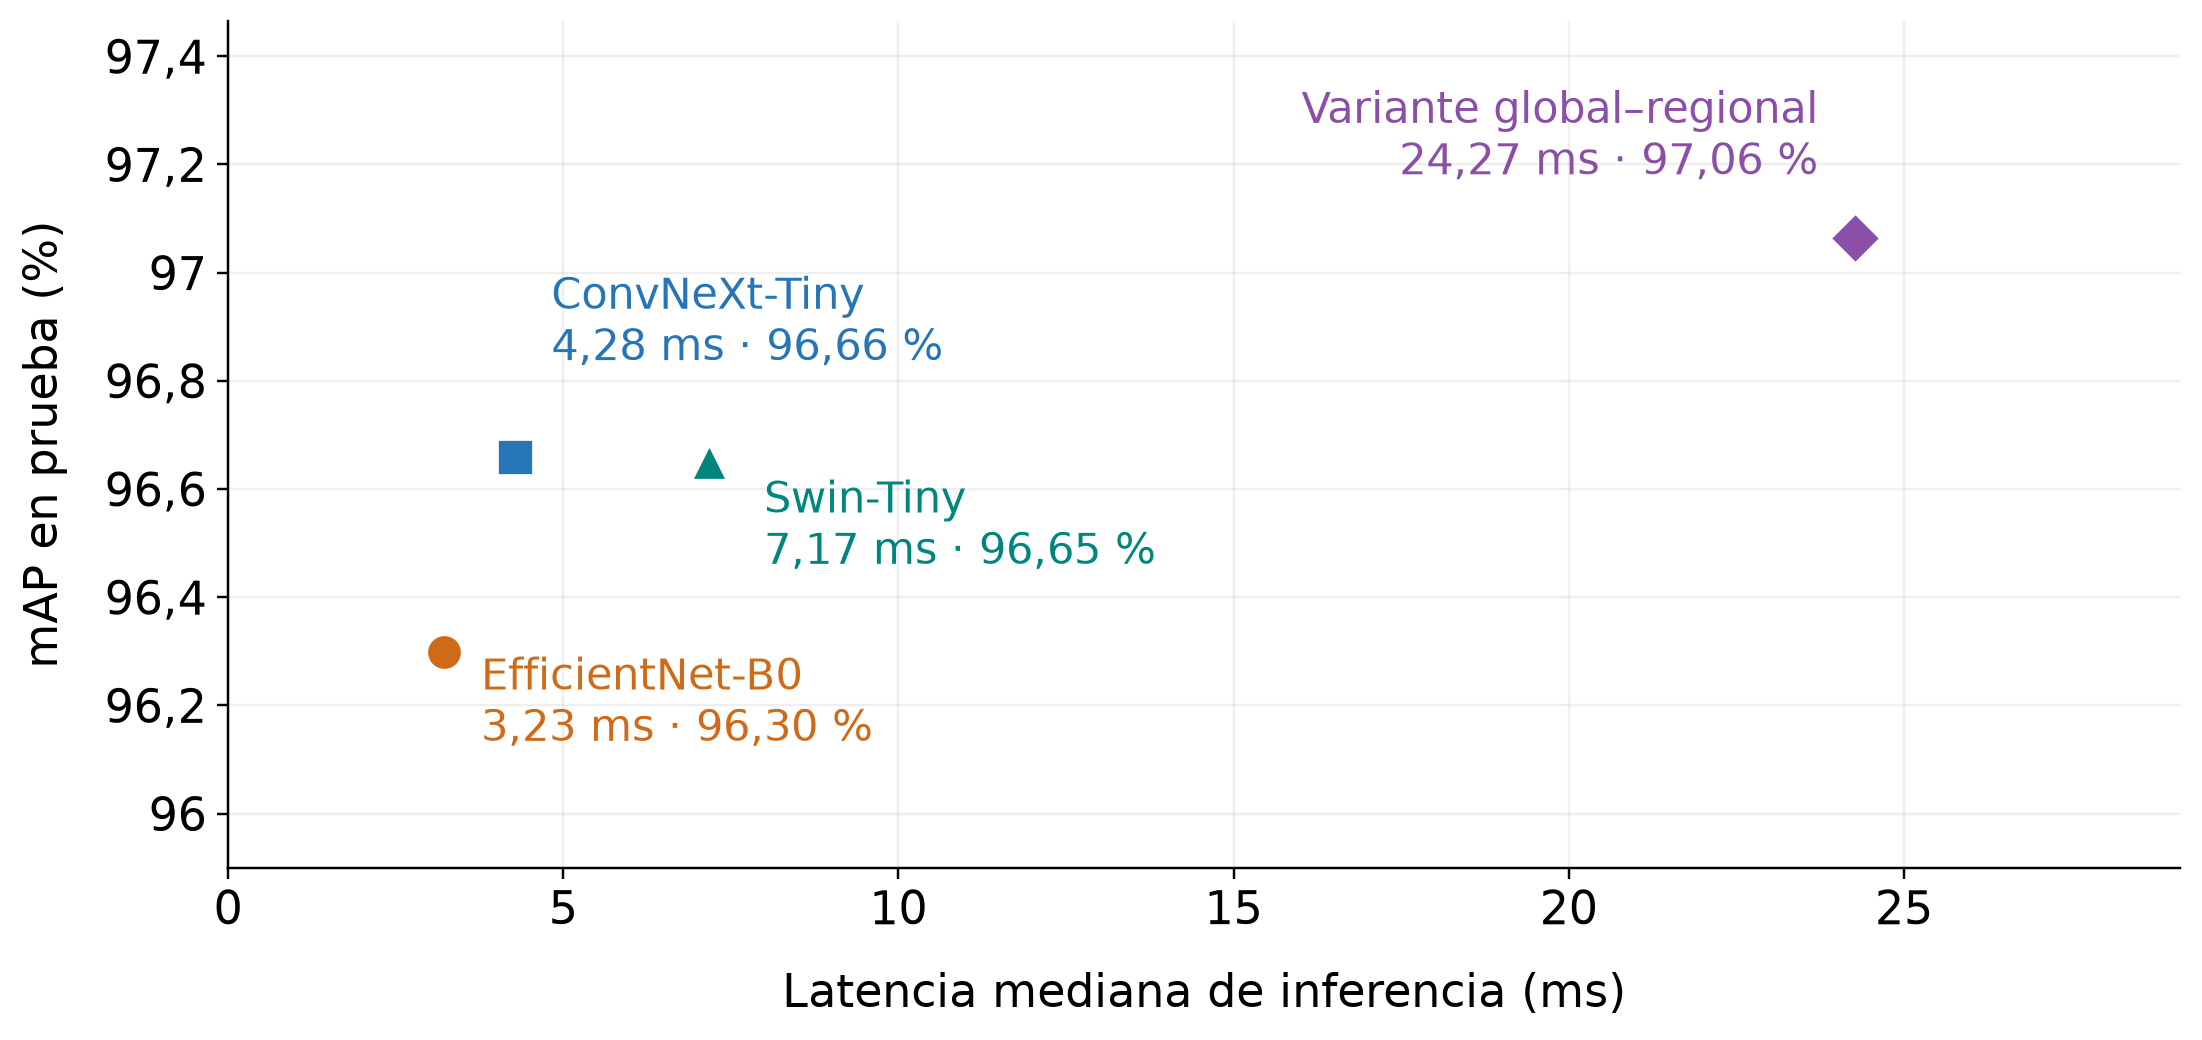

In [10]:
cost_models = [
    ("efficientnet_b0", "EfficientNet-B0", "#cf6a19", "o", (12, -34), "left"),
    ("convnext_tiny", "ConvNeXt-Tiny", "#2575b7", "s", (12, 27), "left"),
    ("swin_t", "Swin-Tiny", "#00867c", "^", (18, -38), "left"),
    ("variant", "Variante global–regional", "#8b4fa8", "D", (-12, 16), "right"),
]
latencies, scores = [], []
with plt.rc_context(
    {
        "font.family": "DejaVu Sans",
        "font.size": 15,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
):
    fig, ax = plt.subplots(figsize=(10.2, 5.2))
    for model, title, colour, marker, offset, align in cost_models:
        if model == "variant":
            milliseconds = cost["timings"]["prepared_forward"]["median_ms"]
        else:
            milliseconds = cost["references_same_runtime"][model]["latency_median_ms"]
        score = reports[model]["overall"]["map"] * 100
        latencies.append(milliseconds)
        scores.append(score)
        ax.scatter(
            milliseconds,
            score,
            s=135,
            color=colour,
            marker=marker,
            edgecolor="white",
            linewidth=0.9,
            zorder=3,
        )
        label = title + "\n" + f"{milliseconds:.2f} ms · {score:.2f} %".replace(".", ",")
        ax.annotate(
            label,
            (milliseconds, score),
            xytext=offset,
            textcoords="offset points",
            ha=align,
            va="bottom",
            fontsize=14,
            color=colour,
        )
    ax.set_xlim(0, max(latencies) * 1.2)
    ax.set_ylim(min(scores) - 0.4, max(scores) + 0.4)
    ax.yaxis.set_major_formatter(FuncFormatter(decimal_label))
    ax.set_xlabel("Latencia mediana de inferencia (ms)", labelpad=12)
    ax.set_ylabel("mAP en prueba (%)", labelpad=12)
    ax.grid(alpha=0.2)

    fig.subplots_adjust(left=0.11, right=0.98, top=0.96, bottom=0.22)
    show_figure(fig)

ConvNeXt y Swin obtienen una mAP similar (96,66 % y 96,65 %), con latencias de 4,28 y 7,17 ms, respectivamente. La variante logra la mayor mAP y también tiene la latencia más alta.

En el [cuaderno 06](06_variant_xai_comparison.ipynb) volvemos a las imágenes de validación para comparar las explicaciones de los cuatro modelos.